# Import Dataset from Kaggle

In [42]:
import kagglehub
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.


# Requirements

In [52]:
#import libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.callbacks import ReduceLROnPlateau

from sklearn.metrics import confusion_matrix, classification_report

In [44]:
print(os.listdir(path))

['cell_images']


In [45]:
data_dir = os.path.join(path,'cell_images')
print(os.listdir(data_dir))

['Uninfected', 'Parasitized', 'cell_images']


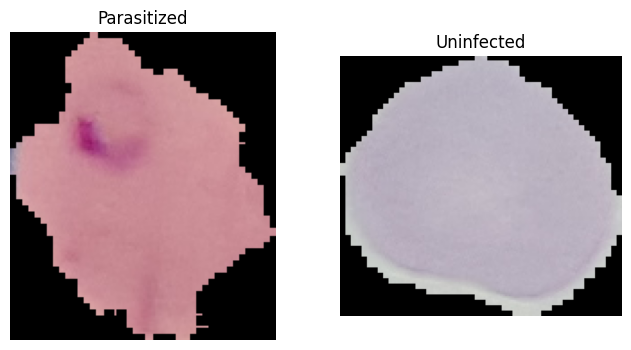

In [46]:
# Show Sample Images

parasitized_folder = os.path.join(data_dir, 'Parasitized')
uninfected_folder = os.path.join(data_dir, 'Uninfected')

img1_name = os.listdir(parasitized_folder)[0]
img2_name = os.listdir(uninfected_folder)[0]


img1 = plt.imread(os.path.join(parasitized_folder, img1_name))
img2 = plt.imread(os.path.join(uninfected_folder, img2_name))

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img1)
plt.title('Parasitized')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2)
plt.title('Uninfected')
plt.axis('off')

plt.show()

In [47]:

# Split Images: 80% Train / 20% Test
import shutil

random.seed(42)
base_dir = '/content/malaria_split'

for cls in ['Parasitized', 'Uninfected']:
    folder = os.path.join(data_dir, cls)

    images = [f for f in os.listdir(folder) if f.endswith('.png')]
    random.shuffle(images)

    split_point = int(0.8 * len(images))
    train_images = images[:split_point]
    test_images = images[split_point:]

    os.makedirs(os.path.join(base_dir, 'train', cls), exist_ok=True)
    os.makedirs(os.path.join(base_dir, 'test', cls), exist_ok=True)

    for img in train_images:
        shutil.copy(os.path.join(folder, img), os.path.join(base_dir, 'train', cls, img))
    for img in test_images:
        shutil.copy(os.path.join(folder, img), os.path.join(base_dir, 'test', cls, img))

    print(cls, "train",len(train_images), "test", len(test_images))

Parasitized train 11023 test 2756
Uninfected train 11023 test 2756


In [48]:
# Prepare Images

train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

train_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)


test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

print("Class Indices:", train_data.class_indices)

Found 17638 images belonging to 2 classes.
Found 4408 images belonging to 2 classes.
Found 5512 images belonging to 2 classes.
Class Indices: {'Parasitized': 0, 'Uninfected': 1}


In [49]:
print("Training:", train_data.classes.sum(), "/", train_data.samples)
print("Validation:", val_data.classes.sum(), "/", val_data.samples)
print("Testing:", test_data.classes.sum(), "/", test_data.samples)

Training: 8819 / 17638
Validation: 2204 / 4408
Testing: 2756 / 5512


Data augmentation

In [50]:
# train_datagen_augmented = ImageDataGenerator(
#     rescale=1./255,
#     validation_split=0.2,
#     rotation_range=20,
#     width_shift_range=0.1,
#     height_shift_range=0.1,
#     shear_range=0.1,
#     zoom_range=0.1,
#     horizontal_flip=True,
#     vertical_flip=True,
#     fill_mode='nearest'
# )

# train_data_augmented = train_datagen_augmented.flow_from_directory(
#     train_dir,
#     target_size=(64, 64),
#     batch_size=32,
#     class_mode='binary',
#     subset='training'
# )
train_data_augmented = train_datagen_augmented.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 17638 images belonging to 2 classes.
Found 4408 images belonging to 2 classes.
Found 5512 images belonging to 2 classes.


# Build Model

In [53]:

model = Sequential()

model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2, 2))
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2, 2))
model.add(GlobalAveragePooling2D())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.4))
model.add(Dense(1, activation='sigmoid'))

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [54]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [55]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [56]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

In [57]:
history = model.fit(
    train_data_augmented,
    validation_data=val_data,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 153s 252ms/step - accuracy: 0.8298 - loss: 0.3854 - val_accuracy: 0.7173 - val_loss: 0.5368 - learning_rate: 3.0000e-04
Epoch 2/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 129s 234ms/step - accuracy: 0.9261 - loss: 0.2099 - val_accuracy: 0.9276 - val_loss: 0.2073 - learning_rate: 3.0000e-04
Epoch 3/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 129s 233ms/step - accuracy: 0.9336 - loss: 0.1947 - val_accuracy: 0.8637 - val_loss: 0.3895 - learning_rate: 3.0000e-04
Epoch 4/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.9365 - loss: 0.1941
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
552/552 ━━━━━━━━━━━━━━━━━━━━ 123s 222ms/step - accuracy: 0.9391 - loss: 0.1868 - val_accuracy: 0.6420 - val_loss: 0.5785 - learning_rate: 3.0000e-04
Epoch 5/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 126s 229ms/step - accuracy: 0.9438 - loss: 0.1742 - val_accuracy: 0.9167 - val_loss: 0.2514 - learning_rate: 1.5000e-04
Epoch 6/15
552/552 ━━━━━━━━━━━━━━━━━━━━ 124s 22

In [58]:
# تقييم النموذج على مجموعة الاختبار
test_loss, test_acc = model.evaluate(test_data)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

173/173 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.9519 - loss: 0.1340
Test Accuracy: 95.19%
Test Loss: 0.1340


173/173 ━━━━━━━━━━━━━━━━━━━━ 11s 59ms/step


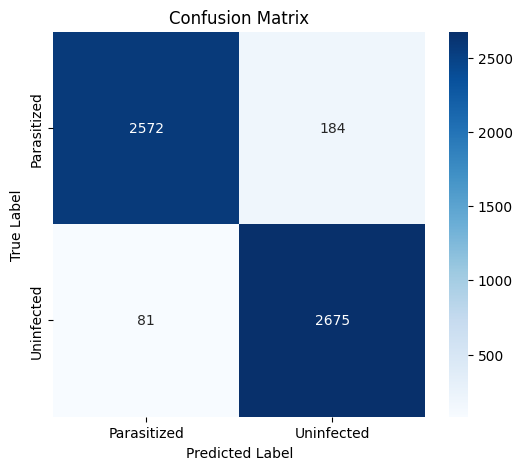

              precision    recall  f1-score   support

 Parasitized       0.97      0.93      0.95      2756
  Uninfected       0.94      0.97      0.95      2756

    accuracy                           0.95      5512
   macro avg       0.95      0.95      0.95      5512
weighted avg       0.95      0.95      0.95      5512



In [59]:

predictions = model.predict(test_data)
predicted_classes = (predictions > 0.5).astype(int).flatten()
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print(classification_report(true_classes, predicted_classes, target_names=class_labels))

%%bash
pip install -q gradio

In [ ]:
import gradio as gr

def predict_malaria(image):
    if image is None:
        return "Please upload an image."

    # Resize image to match model input
    img = tf.image.resize(image, (64, 64))
    # Scale pixel values
    img = img / 255.0
    # Expand dimensions for batch size
    img = tf.expand_dims(img, axis=0)

    # Predict
    prediction = model.predict(img)[0][0]

    # Map prediction to class name based on class_indices
    # {'Parasitized': 0, 'Uninfected': 1}
    if prediction < 0.5:
        confidence = (1 - prediction) * 100
        return f"Parasitized (Confidence: {confidence:.2f}%)"
    else:
        confidence = prediction * 100
        return f"Uninfected (Confidence: {confidence:.2f}%)"

# Create Gradio Interface
interface = gr.Interface(
    fn=predict_malaria,
    inputs=gr.Image(type="numpy"),
    outputs=gr.Textbox(label="Prediction Result"),
    title="Malaria Detection Classifier",
    description="Upload a cell image to detect if it is Parasitized or Uninfected."
)

# Launch the interface
interface.launch(share=True)